# 03 · Preparação dos Dados · Cover Shadow Value (CSV)

Fase 3 do CRISP-DM (capítulo 6 do TFM). Dados: **SkillCorner Open Data** (licença MIT), jogo
1925299, Brisbane Roar – Perth Glory (21/12/2024): tracking a 10 fps, eventos dinâmicos e o
**body pose do jogo inteiro** (25 fps, Hugging Face).

**O que se quer saber nesta fase:**
1. Se pose e tracking ficam bem alinhados quando se junta um ao outro.
2. Como se comportam três versões da orientação do corpo (ombros; ombros e ancas; cabeça), ao
   longo do tempo e entre si.
3. Quantos momentos de posse há e quantos frames alinhados cada um tem.
4. Que parte dos defesas tem pose durante as posses, para várias definições de "defesa relevante".
5. Que valores tomam as características que uma regra de marcação poderia usar.

Este notebook **prepara e mede**: não escolhe entre as versões da orientação nem define a regra
de marcação.

## 1. Preparação

A tabela de trabalho é construída pelo script `projects/cover_shadow/preparar_dados.py`
(reprodutível, lê `data/raw/` sem o alterar):

```
uv run python -m footy.ingest.skillcorner --tracking --pose
uv run python projects/cover_shadow/preparar_dados.py
```

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown
from mplsoccer import Pitch

from footy.ingest import skillcorner as sc
from footy.metrics.orientacao import VERSOES, diferenca_angular, todas_as_orientacoes, vetor
from footy.paths import PROJECTS, output_dir
from footy.transform.skillcorner_pose import FPS_ALINHADO, frames_alinhados_das_posses, posses
from footy.viz.theme import apply_theme, load_brand

sys.path.insert(0, str(PROJECTS / "cover_shadow"))  # para importar o código do projeto

In [2]:
from metrica.marcacao import caracteristicas_de_marcacao
from preparar_dados import caminho_tabela

brand = load_brand()
apply_theme(brand)
FONTE = "SkillCorner Open Data (MIT)"
JOGO = sc.JOGO_PADRAO
FPS_TRACKING = 10

match = sc.ler_match(JOGO)
eventos = sc.ler_eventos(JOGO)
tabela = pd.read_parquet(caminho_tabela(JOGO))
comprimento, largura = sc.dimensoes_campo(match)
nome_da_equipa = {match["home_team"]["id"]: match["home_team"]["short_name"],
                  match["away_team"]["id"]: match["away_team"]["short_name"]}

In [3]:
def credito(fig, extra="", ajustar=True):
    """Crédito da fonte no fundo da figura; `ajustar` abre espaço para ele nos gráficos simples."""
    if ajustar:
        fig.tight_layout(rect=(0, 0.06, 1, 1))
    texto = (extra + " · " if extra else "") + brand.credit(FONTE)
    fig.text(0.5, 0.01, texto, ha="center", va="bottom", color=brand.colors["text_muted"], fontsize=9)


def pt(valor, casas=1):
    """Número com vírgula decimal, para o texto."""
    return f"{valor:.{casas}f}".replace(".", ",")


def novo_campo(figsize=(11, 7.4)):
    campo = Pitch(pitch_type="skillcorner", pitch_length=comprimento, pitch_width=largura,
                  pitch_color=brand.colors["pitch"], line_color=brand.colors["lines"], linewidth=1.2)
    return campo.draw(figsize=figsize)


def histograma(ax, valores, bins, cor, titulo, xlabel, **kw):
    ax.hist(valores.dropna(), bins=bins, color=cor, **kw)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel(xlabel)


NOMES = {"ombros": "ombros", "tronco": "tronco (ombros + ancas)", "cabeca": "cabeça"}
CORES = {"ombros": brand.colors["primary"], "tronco": brand.colors["secondary"], "cabeca": brand.colors["text"]}


def desenhar_corpo(ax, linha, cor):
    """Vista de cima: ombros (traço grosso), ancas, pescoço–ancas, orelhas e nariz."""
    for a, b, espessura in [("lShoulder", "rShoulder", 3.5), ("lHip", "rHip", 2), ("neck", "midHip", 1.5),
                            ("lEar", "rEar", 1.5)]:
        ax.plot([linha[f"{a}_x"], linha[f"{b}_x"]], [linha[f"{a}_y"], linha[f"{b}_y"]],
                color=cor, lw=espessura, solid_capstyle="round", zorder=3)
    ax.scatter([linha["nose_x"]], [linha["nose_y"]], s=16, color=cor, zorder=4)


def desenhar_setas(ax, linha, comprimento_seta=2.2):
    """As três orientações, a sair do centro das ancas (o corpo, não a posição do tracking)."""
    for v in VERSOES:
        fx, fy = vetor(linha[f"orient_{v}"])
        ax.annotate("", xy=(linha["midHip_x"] + comprimento_seta * fx, linha["midHip_y"] + comprimento_seta * fy),
                    xytext=(linha["midHip_x"], linha["midHip_y"]), zorder=5,
                    arrowprops={"arrowstyle": "-|>", "color": CORES[v], "lw": 2})

## 2. A tabela de trabalho

Uma linha por **jogador e frame alinhado** durante as posses de bola. Frame alinhado: um frame
de tracking par, que coincide com um frame de pose múltiplo de 5 (`frame_pose = 2,5 × frame`), o
que dá 5 frames por segundo sem interpolação. Posse: evento `player_possession`, do primeiro ao
último frame.

Colunas: posição do tracking (`x`, `y`, `detetado`), posição que vem no ficheiro da pose
(`x_pose`, `y_pose`, `detetado_pose`), `tem_pose`, as articulações da cabeça, dos ombros e das ancas
(`<articulação>_x`, `_y`, só onde há pose), a bola, a posse (`posse_id`, `portador`,
`equipa_com_bola`) e se o jogador `defende` nesse frame.

In [4]:
print(f"{len(tabela)} linhas · {tabela['frame'].nunique()} frames alinhados "
      f"({pt(tabela['frame'].nunique() / FPS_ALINHADO / 60)} min) · {tabela['jogador'].nunique()} jogadores")
print("Jogadores por frame:", tabela.groupby("frame").size().value_counts().to_dict())
tabela.head(3).T.head(20)

196130 linhas · 8915 frames alinhados (29,7 min) · 32 jogadores
Jogadores por frame: {22: 8915}


,0,1,2
frame,90,90,90
periodo,1,1,1
jogador,11897,50982,50999
x,-30.73,-35.15,34.08
y,-3.26,20.9,1.31
detetado,True,True,False
bola_x,-31.97,-31.97,-31.97
bola_y,19.19,19.19,19.19
posse_id,8_2,8_2,8_2
portador,50982,50982,50982


## 3. Alinhamento entre pose e tracking

### 3.1 A regra dos 2,5 frames

A SkillCorner indica `frame_pose = 2,5 × frame_tracking`. Teste numa janela de 80 s do 1.º tempo:
para cada frame de tracking par, compara-se a posição de cada jogador com a do ficheiro da pose
no frame `2,5 × frame + desvio`, para desvios de −10 a +10 frames de pose (1 frame = 0,04 s).
Se a regra estiver certa, a distância é mínima no desvio 0. Comparam-se também os `timestamp`
dos dois ficheiros.

Timestamps iguais em todos os frames alinhados da janela: True
Desvio com a menor distância: 0 frames de pose


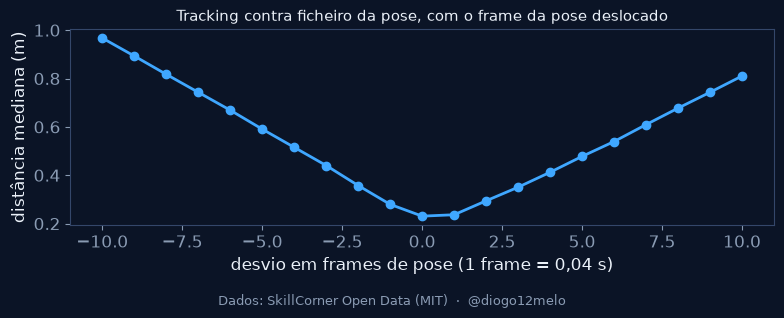

In [5]:
INICIO, FIM = 6000, 6800  # frames de tracking (10.º ao 11.º minuto)
DESVIOS = range(-10, 11)


def posicoes_e_horas(frames_, primeiro, ultimo):
    """{frame: {jogador: (x, y)}} e {frame: timestamp} entre dois frames; para de ler no último."""
    posicoes, horas = {}, {}
    for frame in frames_:
        if frame["frame"] > ultimo:
            break
        if frame["frame"] >= primeiro:
            posicoes[frame["frame"]] = {j["player_id"]: (j["x"], j["y"]) for j in frame["player_data"]}
            horas[frame["frame"]] = frame["timestamp"]
    return posicoes, horas


trk_janela, trk_horas = posicoes_e_horas(sc.frames(sc.caminho(JOGO, "tracking_extrapolated.jsonl")), INICIO, FIM)
pose_janela, pose_horas = posicoes_e_horas(sc.frames(sc.caminho_pose(JOGO)), 2.5 * INICIO - 10, 2.5 * FIM + 10)


def distancia_mediana(desvio):
    distancias = []
    for numero in range(INICIO, FIM + 1, 2):
        a, b = trk_janela.get(numero, {}), pose_janela.get(int(2.5 * numero) + desvio, {})
        distancias += [np.hypot(a[j][0] - b[j][0], a[j][1] - b[j][1]) for j in a if j in b]
    return float(np.median(distancias))


teste_desvio = pd.Series({d: distancia_mediana(d) for d in DESVIOS}, name="distância mediana (m)")
horas_iguais = all(trk_horas[n] == pose_horas[int(2.5 * n)] for n in range(INICIO, FIM + 1, 2))
print(f"Timestamps iguais em todos os frames alinhados da janela: {horas_iguais}")
print(f"Desvio com a menor distância: {teste_desvio.idxmin()} frames de pose")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(teste_desvio.index, teste_desvio.values, color=brand.colors["secondary"], marker="o", lw=2)
ax.set_xlabel("desvio em frames de pose (1 frame = 0,04 s)")
ax.set_ylabel("distância mediana (m)")
ax.set_title("Tracking contra ficheiro da pose, com o frame da pose deslocado", fontsize=11)
credito(fig)
plt.show()

### 3.2 Distância nos frames alinhados

Três comparações, para todos os frames da tabela:
- **tracking ↔ posição no ficheiro da pose:** o ficheiro da pose traz uma posição por jogador
  (o tracking interpolado a 25 fps, segundo a SkillCorner). Nos frames alinhados, a diferença mede
  quanto essa posição difere do ficheiro de tracking publicado no GitHub (`tracking_extrapolated`).
- **tracking ↔ centro das ancas (`midHip`):** onde está o corpo reconstruído pela pose face à
  posição do tracking. A SkillCorner avisa que os dois são gerados em separado.
- **ficheiro da pose ↔ centro das ancas:** se a posição que vem com a pose acompanha o corpo.

In [6]:
tabela["dist_ficheiro_pose"] = np.hypot(tabela["x"] - tabela["x_pose"], tabela["y"] - tabela["y_pose"])
tabela["dist_ancas"] = np.hypot(tabela["x"] - tabela["midHip_x"], tabela["y"] - tabela["midHip_y"])
tabela["dist_pose_ancas"] = np.hypot(tabela["x_pose"] - tabela["midHip_x"], tabela["y_pose"] - tabela["midHip_y"])


def resumo_distancias(series):
    return pd.DataFrame({
        nome: {"jogador-frames": s.notna().sum(), "mediana (m)": s.median(), "p90 (m)": s.quantile(0.9),
               "p99 (m)": s.quantile(0.99), "% acima de 1 m": 100 * (s > 1).mean()}
        for nome, s in series.items()
    }).T.round(2)


detetado = tabela["detetado"]
resumo_distancias({
    "tracking ↔ ficheiro da pose · detetados": tabela.loc[detetado, "dist_ficheiro_pose"],
    "tracking ↔ ficheiro da pose · não detetados": tabela.loc[~detetado, "dist_ficheiro_pose"],
    "tracking ↔ centro das ancas · com pose": tabela.loc[tabela["tem_pose"], "dist_ancas"],
    "ficheiro da pose ↔ centro das ancas · com pose": tabela.loc[tabela["tem_pose"], "dist_pose_ancas"],
})

,jogador-frames,mediana (m),p90 (m),p99 (m),% acima de 1 m
tracking ↔ ficheiro da pose · detetados,121037.0,0.19,0.51,2.72,2.54
tracking ↔ ficheiro da pose · não detetados,75093.0,0.43,2.18,12.72,23.33
tracking ↔ centro das ancas · com pose,120909.0,0.22,0.54,4.05,3.02
ficheiro da pose ↔ centro das ancas · com pose,120909.0,0.08,0.14,0.23,0.00


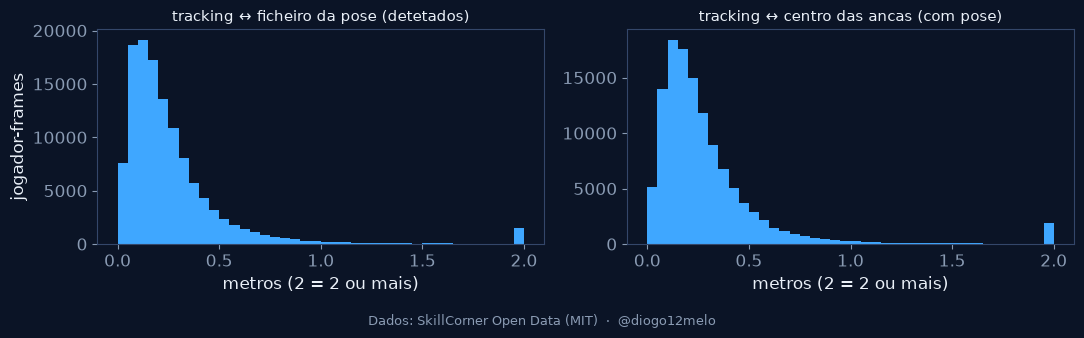

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
bins = np.arange(0, 2.05, 0.05)
histograma(axes[0], tabela.loc[detetado, "dist_ficheiro_pose"].clip(upper=2), bins,
           brand.colors["secondary"], "tracking ↔ ficheiro da pose (detetados)", "metros (2 = 2 ou mais)")
histograma(axes[1], tabela.loc[tabela["tem_pose"], "dist_ancas"].clip(upper=2), bins,
           brand.colors["secondary"], "tracking ↔ centro das ancas (com pose)", "metros (2 = 2 ou mais)")
axes[0].set_ylabel("jogador-frames")
credito(fig)
plt.show()

### 3.3 Onde o tracking e o corpo não coincidem

Jogador-frames com pose em que a posição do tracking fica a mais de 3 m do centro das ancas,
separados pela deteção em cada ficheiro (`detetado` no tracking, `detetado_pose` no ficheiro da
pose).

In [8]:
LONGE = 3  # metros
com_pose_todos = tabela[tabela["tem_pose"]]
pd.crosstab([com_pose_todos["detetado"].rename("detetado (tracking)"),
             com_pose_todos["detetado_pose"].rename("detetado (pose)")],
            com_pose_todos["dist_ancas"] > LONGE, margins=True).rename(
    columns={False: f"até {LONGE} m", True: f"mais de {LONGE} m", "All": "total"})

dist_ancas                           até 3 m  mais de 3 m   total
detetado (tracking) detetado (pose)                              
False               True                 908          872    1780
True                False                  1            0       1
                    True              118609          519  119128
All                                   119518         1391  120909

**Exemplo:** o frame com mais jogadores nesta situação. Cada jogador com pose aparece com o corpo
(ombros, ancas, nariz) e, quando a posição do tracking fica a mais de 1 m, um círculo nessa
posição ligado ao corpo por uma linha tracejada.

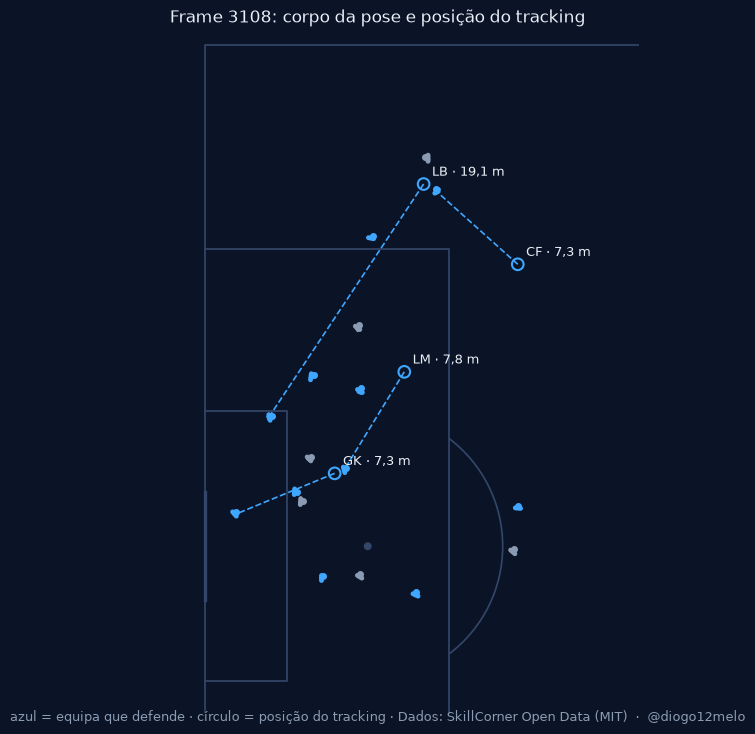

In [9]:
def desenhar_desacordo(numero, margem=8):
    jogadores = tabela[(tabela["frame"] == numero) & tabela["tem_pose"]]
    fig, ax = novo_campo()
    for _, linha in jogadores.iterrows():
        cor = brand.colors["secondary"] if linha["defende"] else brand.colors["text_muted"]
        desenhar_corpo(ax, linha, cor)
        if linha["dist_ancas"] > 1:
            ax.plot([linha["x"], linha["midHip_x"]], [linha["y"], linha["midHip_y"]], ls="--", lw=1.2,
                    color=cor, zorder=2)
            ax.scatter([linha["x"]], [linha["y"]], s=70, facecolors="none", edgecolors=cor, lw=1.5, zorder=3)
            ax.annotate(f"{linha['posicao']} · {pt(linha['dist_ancas'])} m", (linha["x"], linha["y"]),
                        xytext=(6, 6), textcoords="offset points", color=brand.colors["text"], fontsize=9)
    ax.set_xlim(jogadores[["x", "midHip_x"]].min().min() - margem, jogadores[["x", "midHip_x"]].max().max() + margem)
    ax.set_ylim(jogadores[["y", "midHip_y"]].min().min() - margem, jogadores[["y", "midHip_y"]].max().max() + margem)
    ax.set_title(f"Frame {numero}: corpo da pose e posição do tracking", fontsize=12)
    credito(fig, "azul = equipa que defende · círculo = posição do tracking", ajustar=False)
    plt.show()


frame_desacordo = int(com_pose_todos[com_pose_todos["dist_ancas"] > LONGE].groupby("frame").size().idxmax())
desenhar_desacordo(frame_desacordo)

## 4. Orientação do corpo: três versões

Calculadas em `footy.metrics.orientacao`, em graus no referencial do campo (0° = sentido +x,
anti-horário):
- **ombros:** perpendicular ao segmento ombro esquerdo → ombro direito (a versão da fase 2);
- **tronco:** a mesma ideia com ombros e ancas, com o mesmo peso;
- **cabeça:** do ponto médio entre as orelhas para o nariz.

Só entram os jogador-frames com pose (todas as articulações estão presentes quando há pose).

In [10]:
com_pose = tabela[tabela["tem_pose"]].copy()
com_pose = com_pose.join(todas_as_orientacoes(com_pose))


def nariz_a_frente(t, versao):
    """O nariz está à frente do pescoço segundo esta orientação? (a verificação da fase 2)"""
    fx, fy = vetor(t[f"orient_{versao}"])
    return (t["nose_x"] - t["neck_x"]) * fx + (t["nose_y"] - t["neck_y"]) * fy > 0


pd.Series({NOMES[v]: 100 * nariz_a_frente(com_pose, v).mean() for v in ("ombros", "tronco")},
          name="% com o nariz à frente do pescoço").round(1)

ombros                     99.9
tronco (ombros + ancas)    99.9
Name: % com o nariz à frente do pescoço, dtype: float64

A versão da cabeça usa o próprio nariz, por isso fica de fora desta verificação.

### 4.1 Concordância entre versões

Para cada par de versões, a diferença angular em cada jogador-frame (0° = apontam para o mesmo
lado, 180° = opostas).

In [11]:
PARES = [("ombros", "tronco"), ("ombros", "cabeca"), ("tronco", "cabeca")]
diferencas = pd.DataFrame({
    f"{NOMES[a]} ↔ {NOMES[b]}": diferenca_angular(com_pose[f"orient_{a}"], com_pose[f"orient_{b}"])
    for a, b in PARES
}, index=com_pose.index)

pd.DataFrame({
    "mediana (°)": diferencas.median(), "p90 (°)": diferencas.quantile(0.9),
    "% até 20°": 100 * (diferencas <= 20).mean(), "% acima de 90°": 100 * (diferencas > 90).mean(),
}).round(1)

,mediana (°),p90 (°),% até 20°,% acima de 90°
ombros ↔ tronco (ombros + ancas),5.6,13.1,99.2,0.0
ombros ↔ cabeça,17.9,39.7,54.9,0.2
tronco (ombros + ancas) ↔ cabeça,18.9,43.4,52.4,0.2


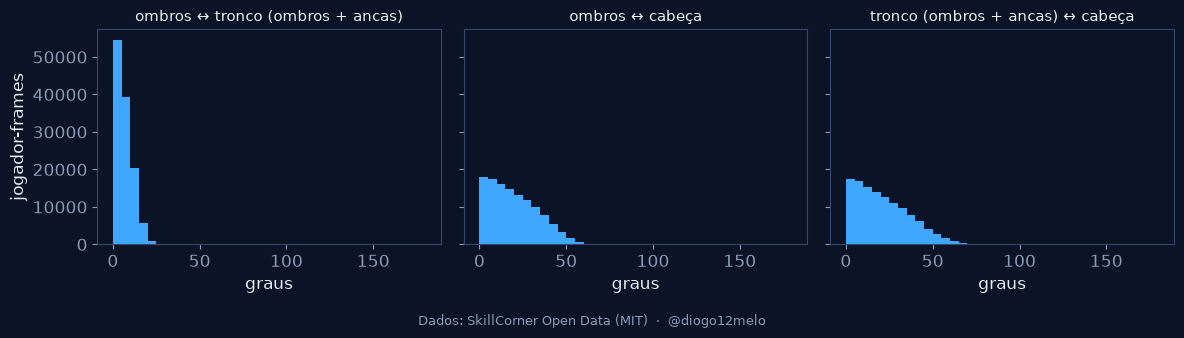

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, coluna in zip(axes, diferencas.columns):
    histograma(ax, diferencas[coluna], range(0, 181, 5), brand.colors["secondary"], coluna, "graus")
axes[0].set_ylabel("jogador-frames")
credito(fig)
plt.show()

### 4.2 Ao longo do tempo

Quanto muda cada versão de um frame alinhado para o seguinte (0,2 s), para o mesmo jogador
dentro da mesma posse e com pose nos dois frames. Um jogador real pode rodar depressa, mas uma
versão que treme mais muda mais de frame para frame mesmo quando o jogador está estável.

In [13]:
def variacao_entre_frames(t, coluna):
    """Diferença angular para o frame alinhado anterior do mesmo jogador, na mesma posse."""
    t = t.sort_values(["jogador", "frame"])
    seguido = ((t["jogador"] == t["jogador"].shift()) & (t["posse_id"] == t["posse_id"].shift())
               & (t["frame"].diff() == 2))
    return pd.Series(diferenca_angular(t[coluna], t[coluna].shift()), index=t.index).where(seguido)


variacoes = pd.DataFrame({NOMES[v]: variacao_entre_frames(com_pose, f"orient_{v}") for v in VERSOES})
pd.DataFrame({
    "pares de frames": variacoes.notna().sum(), "mediana (°)": variacoes.median(),
    "p90 (°)": variacoes.quantile(0.9), "% acima de 45°": 100 * (variacoes > 45).mean(),
}).round(1)

,pares de frames,mediana (°),p90 (°),% acima de 45°
ombros,106695,11.1,28.9,1.2
tronco (ombros + ancas),106680,6.6,19.7,0.8
cabeça,106700,8.2,29.9,3.9


**Exemplo:** o defesa e a posse com mais frames seguidos com pose. As três versões ao longo da
posse (os ângulos estão "desenrolados" para não saltarem de 359° para 0°).

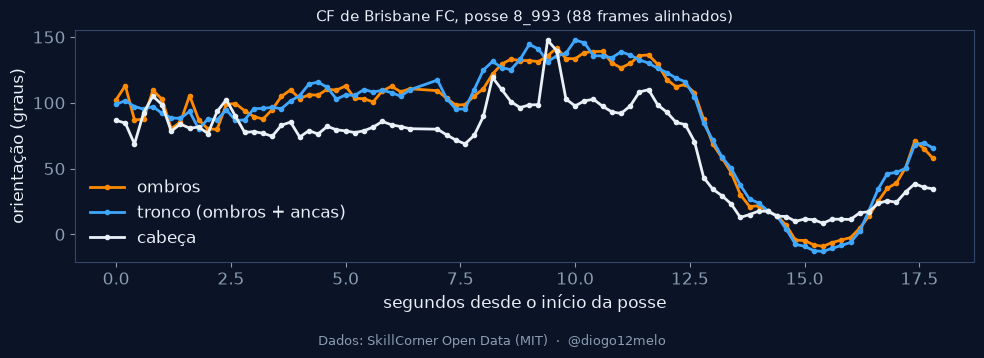

In [14]:
defesas_com_pose = com_pose[com_pose["defende"]]
maior = defesas_com_pose.groupby(["jogador", "posse_id"]).size().idxmax()
exemplo = defesas_com_pose[(defesas_com_pose["jogador"] == maior[0])
                           & (defesas_com_pose["posse_id"] == maior[1])].sort_values("frame")
ficha = tabela.loc[tabela["jogador"] == maior[0], ["posicao", "equipa"]].iloc[0]
segundos = (exemplo["frame"] - exemplo["frame"].iloc[0]) / FPS_TRACKING

fig, ax = plt.subplots(figsize=(10, 3.6))
for v in VERSOES:
    desenrolado = np.degrees(np.unwrap(np.radians(exemplo[f"orient_{v}"].to_numpy())))
    ax.plot(segundos, desenrolado, color=CORES[v], lw=2, marker="o", ms=3, label=NOMES[v])
ax.set_xlabel("segundos desde o início da posse")
ax.set_ylabel("orientação (graus)")
ax.set_title(f"{ficha['posicao']} de {nome_da_equipa[ficha['equipa']]}, posse {maior[1]} "
             f"({len(exemplo)} frames alinhados)", fontsize=11)
ax.legend(frameon=False)
credito(fig)
plt.show()

### 4.3 Exemplos visuais

Vista de cima de um frame (o que tem mais defesas com pose). Cada defesa com pose aparece com a
linha dos ombros, a das ancas e o nariz; as três setas são as três versões. Atacantes em
cinzento, bola em branco.

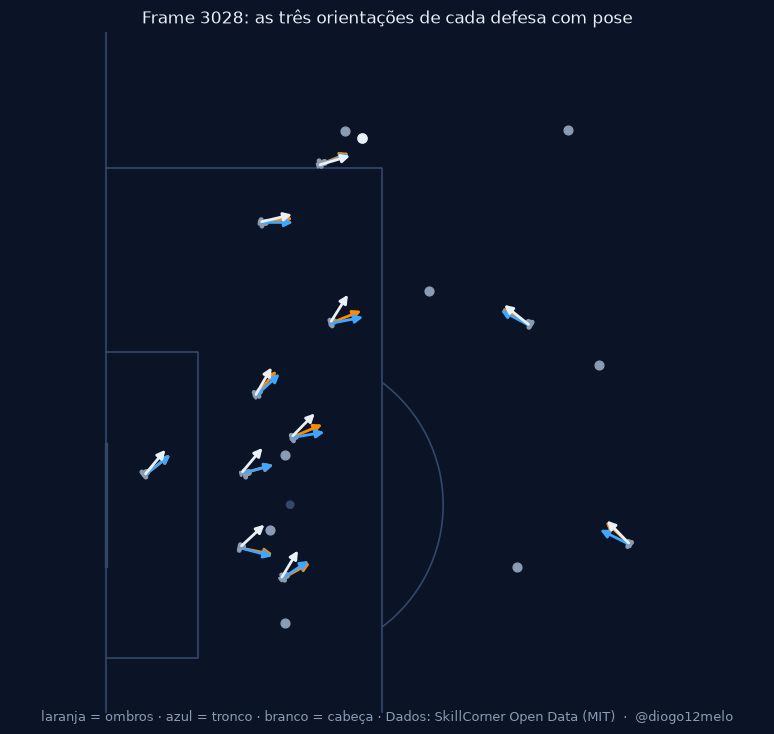

In [15]:
def desenhar_frame_orientacoes(numero, margem=8):
    jogadores = tabela[tabela["frame"] == numero]
    poses = com_pose[(com_pose["frame"] == numero) & com_pose["defende"]]
    fig, ax = novo_campo()
    atacantes = jogadores[~jogadores["defende"]]
    ax.scatter(atacantes["x"], atacantes["y"], s=40, color=brand.colors["text_muted"], zorder=2)
    for _, linha in poses.iterrows():
        desenhar_corpo(ax, linha, brand.colors["text_muted"])
        desenhar_setas(ax, linha)
    bola = jogadores.iloc[0]
    ax.scatter([bola["bola_x"]], [bola["bola_y"]], s=45, color=brand.colors["text"], zorder=6)
    ax.set_xlim(poses["midHip_x"].min() - margem, poses["midHip_x"].max() + margem)
    ax.set_ylim(poses["midHip_y"].min() - margem, poses["midHip_y"].max() + margem)
    credito(fig, "laranja = ombros · azul = tronco · branco = cabeça", ajustar=False)
    return fig, ax


frame_exemplo = int(defesas_com_pose.groupby("frame").size().idxmax())
fig, ax = desenhar_frame_orientacoes(frame_exemplo)
ax.set_title(f"Frame {frame_exemplo}: as três orientações de cada defesa com pose", fontsize=12)
fig.savefig(output_dir("cover_shadow") / "fase3_orientacoes.png", dpi=150)
plt.show()

**Os dois casos de maior desacordo entre tronco e cabeça** (um frame por jogador, defesas), com o
caminho de ±1 s à volta desse frame em cinzento. Permite ver se a cabeça está virada para outro
lado que não o do tronco ou se a pose está mal reconstruída.

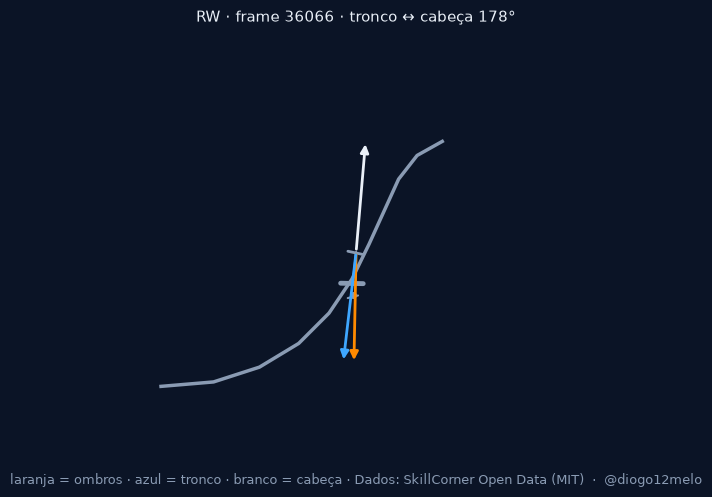

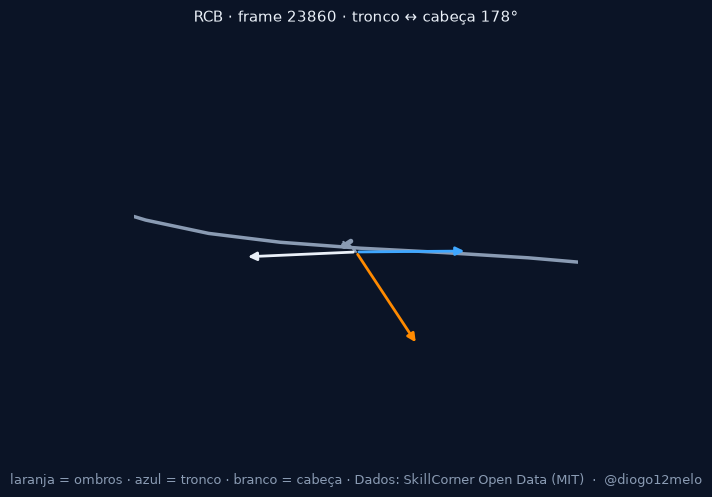

In [16]:
def desenhar_caso(linha, margem=3):
    fig, ax = novo_campo(figsize=(7, 5))
    caminho = tabela[(tabela["jogador"] == linha["jogador"])
                     & tabela["frame"].between(linha["frame"] - FPS_TRACKING, linha["frame"] + FPS_TRACKING)]
    # o caminho usa a posição do ficheiro da pose, que acompanha o corpo (secção 3.2)
    ax.plot(caminho["x_pose"], caminho["y_pose"], color=brand.colors["text_muted"], lw=2.5, zorder=2)
    desenhar_corpo(ax, linha, brand.colors["text_muted"])
    desenhar_setas(ax, linha, comprimento_seta=1.5)
    ax.set_xlim(linha["midHip_x"] - margem, linha["midHip_x"] + margem)
    ax.set_ylim(linha["midHip_y"] - margem, linha["midHip_y"] + margem)
    diferenca = diferenca_angular(linha["orient_tronco"], linha["orient_cabeca"])
    ax.set_title(f"{linha['posicao']} · frame {int(linha['frame'])} · tronco ↔ cabeça {diferenca:.0f}°",
                 fontsize=11)
    credito(fig, "laranja = ombros · azul = tronco · branco = cabeça", ajustar=False)
    plt.show()


desacordo = defesas_com_pose.assign(
    tronco_cabeca=diferencas.loc[defesas_com_pose.index, "tronco (ombros + ancas) ↔ cabeça"])
for _, linha in (desacordo.sort_values("tronco_cabeca", ascending=False)
                 .drop_duplicates("jogador").head(2).iterrows()):
    desenhar_caso(linha)

## 5. Momentos de posse

Cada evento `player_possession` é um momento em que um jogador tem a bola controlada (decisão D6).
Uma posse muito curta pode não ter nenhum frame alinhado: uma posse de 0 s num frame ímpar não
coincide com nenhum frame de pose. Há também frames dentro de posses em que o tracking não traz
jogadores.

In [17]:
tabela_posses = posses(eventos)
momentos = frames_alinhados_das_posses(tabela_posses)
frames_por_posse = tabela.groupby("posse_id")["frame"].nunique()
tabela_posses["frames_alinhados"] = tabela_posses["posse_id"].map(frames_por_posse).fillna(0).astype(int)
tabela_posses["duracao_s"] = (tabela_posses["frame_fim"] - tabela_posses["frame_inicio"]) / FPS_TRACKING
frames_sem_jogadores = len(set(momentos["frame"]) - set(tabela["frame"]))

resumo_posses = tabela_posses.groupby(tabela_posses["equipa_com_bola"].map(nome_da_equipa)).agg(
    posses=("posse_id", "size"),
    sem_frames_alinhados=("frames_alinhados", lambda f: int((f == 0).sum())),
    frames_alinhados=("frames_alinhados", "sum"),
    duracao_mediana_s=("duracao_s", "median"),
)
resumo_posses.loc["total"] = [len(tabela_posses), int((tabela_posses["frames_alinhados"] == 0).sum()),
                              int(tabela_posses["frames_alinhados"].sum()), tabela_posses["duracao_s"].median()]
print(f"Frames alinhados em posse sem jogadores no tracking (ficam de fora): {frames_sem_jogadores}")
resumo_posses

Frames alinhados em posse sem jogadores no tracking (ficam de fora): 14


,posses,sem_frames_alinhados,frames_alinhados,duracao_mediana_s
equipa_com_bola,,,,
Brisbane FC,663.0,78.0,5548.0,1.2
Perth Glory,391.0,52.0,3367.0,1.1
total,1054.0,130.0,8915.0,1.2


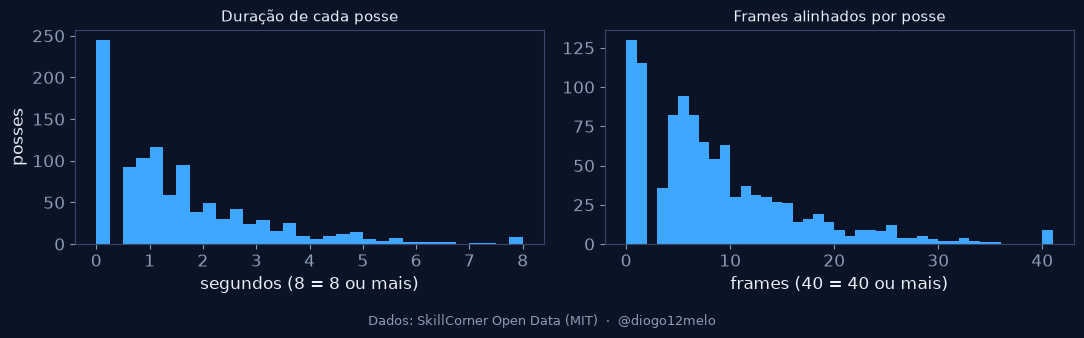

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
histograma(axes[0], tabela_posses["duracao_s"].clip(upper=8), np.arange(0, 8.25, 0.25), brand.colors["secondary"],
           "Duração de cada posse", "segundos (8 = 8 ou mais)")
histograma(axes[1], tabela_posses["frames_alinhados"].clip(upper=40), range(42), brand.colors["secondary"],
           "Frames alinhados por posse", "frames (40 = 40 ou mais)")
axes[0].set_ylabel("posses")
credito(fig)
plt.show()

## 6. Cobertura do body pose nos defesas durante as posses

Defesas: os jogadores da equipa sem a bola em cada frame. Para várias definições de "defesa
relevante" mede-se:
- a parte dos defesa-frames com pose;
- a parte dos frames em que **todos** os defesas relevantes têm pose;
- a parte das posses em que isso acontece em pelo menos um frame, e em todos os frames.

A distância é medida à bola (posição do tracking).

In [19]:
defesas = tabela[tabela["defende"]].copy()
defesas["dist_bola"] = np.hypot(defesas["x"] - defesas["bola_x"], defesas["y"] - defesas["bola_y"])

DEFINICOES = {
    "todos os defesas": defesas["jogador"].notna(),
    "jogadores de campo (sem GR)": defesas["posicao"] != "GK",
    "a menos de 30 m da bola": defesas["dist_bola"] < 30,
    "a menos de 20 m da bola": defesas["dist_bola"] < 20,
    "a menos de 10 m da bola": defesas["dist_bola"] < 10,
}


def cobertura(relevantes):
    por_frame = relevantes.groupby("frame")
    todos_com_pose = por_frame["tem_pose"].all()
    posse_do_frame = por_frame["posse_id"].first()
    por_posse = todos_com_pose.groupby(posse_do_frame)
    return {
        "frames com algum relevante": len(todos_com_pose),
        "relevantes por frame (média)": por_frame.size().mean(),
        "% defesa-frames com pose": 100 * relevantes["tem_pose"].mean(),
        "% defesa-frames detetados": 100 * relevantes["detetado"].mean(),
        "% frames com todos com pose": 100 * todos_com_pose.mean(),
        "% posses: todos com pose em ≥ 1 frame": 100 * por_posse.any().mean(),
        "% posses: todos com pose em todos os frames": 100 * por_posse.all().mean(),
    }


pd.DataFrame({nome: cobertura(defesas[filtro]) for nome, filtro in DEFINICOES.items()}).T.round(1)

,frames com algum relevante,relevantes por frame (média),% defesa-frames com pose,% defesa-frames detetados,% frames com todos com pose,% posses: todos com pose em ≥ 1 frame,% posses: todos com pose em todos os frames
todos os defesas,8915.0,11.0,64.5,64.5,9.4,12.9,6.4
jogadores de campo (sem GR),8915.0,10.0,68.5,68.5,16.9,23.6,10.3
a menos de 30 m da bola,8915.0,7.3,82.8,82.9,37.0,49.1,22.4
a menos de 20 m da bola,8826.0,4.5,92.7,92.8,78.4,87.3,63.7
a menos de 10 m da bola,7129.0,2.2,97.2,97.6,94.4,97.8,89.4


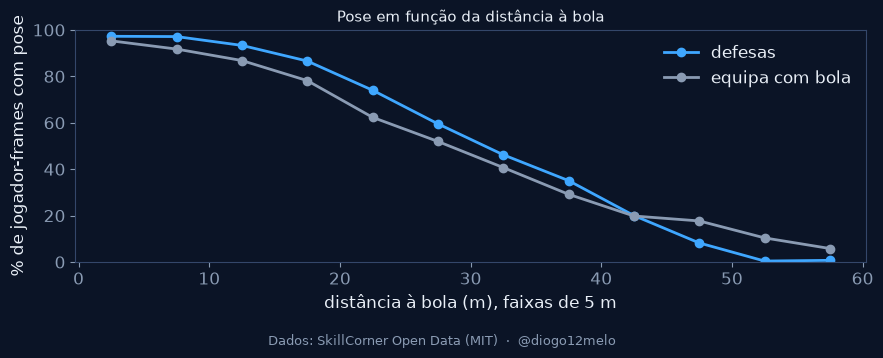

In [20]:
faixas = np.arange(0, 65, 5)
atacantes = tabela[~tabela["defende"]].assign(
    dist_bola=lambda t: np.hypot(t["x"] - t["bola_x"], t["y"] - t["bola_y"]))


def pose_por_distancia(t):
    return t.groupby(pd.cut(t["dist_bola"], faixas), observed=False)["tem_pose"].mean() * 100


fig, ax = plt.subplots(figsize=(9, 3.6))
centros = faixas[:-1] + 2.5
ax.plot(centros, pose_por_distancia(defesas), color=brand.colors["secondary"], marker="o", lw=2, label="defesas")
ax.plot(centros, pose_por_distancia(atacantes), color=brand.colors["text_muted"], marker="o", lw=2,
        label="equipa com bola")
ax.set_xlabel("distância à bola (m), faixas de 5 m")
ax.set_ylabel("% de jogador-frames com pose")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.set_title("Pose em função da distância à bola", fontsize=11)
credito(fig)
plt.show()

## 7. Marcação: características candidatas

Calculadas em `metrica/marcacao.py` para cada defesa e frame. Nenhuma regra é aplicada:
- **distância ao atacante mais próximo** (`dist_atacante`, m) e ao portador (`dist_portador`);
- **lado da baliza** (`lado_da_baliza`): o defesa está mais perto do centro da própria baliza do
  que esse atacante;
- **persistência** (`persistencia_s`): segundos seguidos, na mesma posse, em que esse atacante é o
  mais próximo;
- **corpo virado para o atacante / para o portador** (`desvio_atacante_<versão>`,
  `desvio_portador_<versão>`): ângulo entre a orientação e a direção para cada um; 0° = de frente,
  180° = de costas. Só para defesas com pose.

In [21]:
marcacao = caracteristicas_de_marcacao(tabela, match)
CONTINUAS = ["dist_atacante", "dist_portador", "persistencia_s"]
resumo = marcacao[CONTINUAS].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T
resumo.round(2)

,count,mean,std,min,10%,25%,50%,75%,90%,max
dist_atacante,98065.0,7.32,6.49,0.03,2.08,3.46,5.63,8.66,13.34,66.93
dist_portador,98065.0,25.43,14.92,0.03,7.42,14.20,23.83,34.31,44.97,89.92
persistencia_s,98065.0,3.03,3.26,0.20,0.80,1.40,2.20,3.60,5.20,25.00


In [22]:
print(f"Do lado da baliza: {100 * marcacao['lado_da_baliza'].mean():.1f}% dos defesa-frames")
desvios = marcacao[[f"desvio_{alvo}_{v}" for alvo in ("atacante", "portador") for v in VERSOES]]
pd.DataFrame({
    "defesa-frames": desvios.notna().sum(),
    "mediana (°)": desvios.median(),
    "% até 45°": 100 * (desvios <= 45).sum() / desvios.notna().sum(),
    "% acima de 135°": 100 * (desvios > 135).sum() / desvios.notna().sum(),
}).round(1)

Do lado da baliza: 66.2% dos defesa-frames


,defesa-frames,mediana (°),% até 45°,% acima de 135°
desvio_atacante_ombros,63236,76.0,31.4,20.4
desvio_atacante_tronco,63231,76.4,31.1,20.8
desvio_atacante_cabeca,63239,72.1,34.2,17.6
desvio_portador_ombros,63236,33.3,64.4,0.7
desvio_portador_tronco,63231,34.8,62.6,0.7
desvio_portador_cabeca,63239,18.0,85.9,0.7


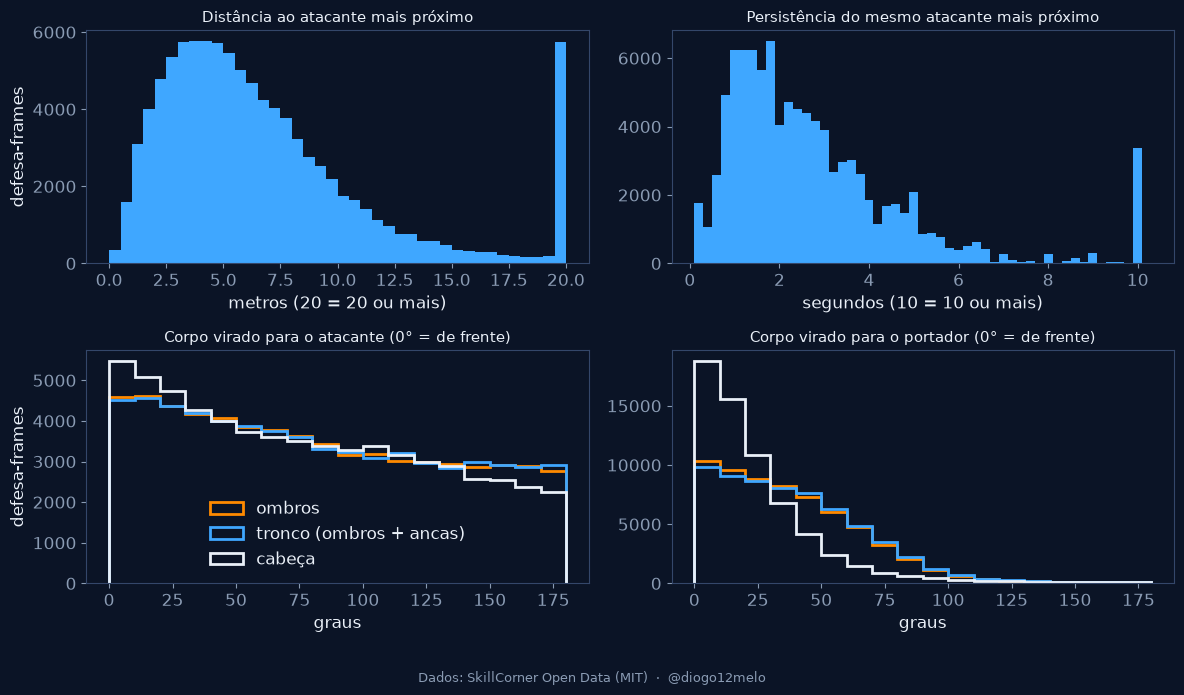

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
histograma(axes[0, 0], marcacao["dist_atacante"].clip(upper=20), np.arange(0, 20.5, 0.5), brand.colors["secondary"],
           "Distância ao atacante mais próximo", "metros (20 = 20 ou mais)")
histograma(axes[0, 1], marcacao["persistencia_s"].clip(upper=10), np.arange(0.1, 10.4, 0.2), brand.colors["secondary"],
           "Persistência do mesmo atacante mais próximo", "segundos (10 = 10 ou mais)")
for ax, alvo in zip(axes[1], ("atacante", "portador")):
    for v in VERSOES:
        ax.hist(marcacao[f"desvio_{alvo}_{v}"].dropna(), bins=range(0, 181, 10), histtype="step", lw=2,
                color=CORES[v], label=NOMES[v])
    ax.set_title(f"Corpo virado para o {alvo} (0° = de frente)", fontsize=11)
    ax.set_xlabel("graus")
axes[1, 0].legend(frameon=False)
for ax in axes[:, 0]:
    ax.set_ylabel("defesa-frames")
fig.tight_layout(rect=(0, 0.03, 1, 1))
credito(fig)
plt.show()

**Relação entre distância e persistência.** Mediana da persistência por faixa de distância ao
atacante mais próximo (só descreve como as duas medidas variam em conjunto).

In [24]:
faixas_dist = [0, 1, 2, 3, 5, 8, 12, 20, 100]
marcacao.groupby(pd.cut(marcacao["dist_atacante"], faixas_dist), observed=False).agg(
    defesa_frames=("persistencia_s", "size"),
    persistencia_mediana_s=("persistencia_s", "median"),
    pct_lado_da_baliza=("lado_da_baliza", lambda s: 100 * s.mean()),
    desvio_atacante_tronco_mediano=("desvio_atacante_tronco", "median"),
).round(1)

,defesa_frames,persistencia_mediana_s,pct_lado_da_baliza,desvio_atacante_tronco_mediano
dist_atacante,,,,
"(0, 1]",1930,2.4,60.3,66.3
"(1, 2]",7112,2.6,64.3,67.6
"(2, 3]",10139,2.4,64.7,72.4
"(3, 5]",22996,2.4,61.6,79.0
"(5, 8]",27192,2.2,61.0,80.8
"(8, 12]",16612,2.0,65.6,82.7
"(12, 20]",6493,2.0,83.3,59.2
"(20, 100]",5591,2.4,99.6,37.1


**Exemplos.** Para cada equipa a defender, o frame com mais defesas com pose a menos de 30 m da
bola. Linhas finas: cada defesa (posição do tracking, com a sigla) ligado ao atacante mais
próximo. Corpo e setas: a pose, com as três orientações. A tabela a seguir a cada campo dá as
características de cada defesa nesse frame.

In [25]:
def desenhar_exemplo_marcacao(numero, margem=8):
    jogadores = tabela[tabela["frame"] == numero]
    defs = marcacao[marcacao["frame"] == numero]
    fig, ax = novo_campo()
    atacantes_ = jogadores[~jogadores["defende"]]
    portador = jogadores[jogadores["jogador"] == jogadores["portador"]]
    ax.scatter(atacantes_["x"], atacantes_["y"], s=40, color=brand.colors["text_muted"], zorder=2)
    ax.scatter(portador["x"], portador["y"], s=110, facecolors="none", edgecolors=brand.colors["text"], lw=1.5, zorder=2)
    for _, d in defs.iterrows():
        # as características usam a posição do tracking: é dela que sai a linha para o atacante
        ax.plot([d["x"], d["atacante_x"]], [d["y"], d["atacante_y"]], color=brand.colors["lines"], lw=1, zorder=1)
        if d["tem_pose"]:
            desenhar_corpo(ax, d, brand.colors["text_muted"])
            desenhar_setas(ax, d)
            if d["dist_ancas"] > 1:
                ax.plot([d["x"], d["midHip_x"]], [d["y"], d["midHip_y"]], ls="--", lw=1,
                        color=brand.colors["text_muted"], zorder=2)
        else:
            ax.scatter([d["x"]], [d["y"]], s=40, facecolors="none", edgecolors=brand.colors["secondary"], zorder=3)
        ax.annotate(d["posicao"], (d["x"], d["y"]), xytext=(6, -12), textcoords="offset points",
                    color=brand.colors["text"], fontsize=8, zorder=6)
    ax.scatter([jogadores["bola_x"].iloc[0]], [jogadores["bola_y"].iloc[0]], s=45, color=brand.colors["text"], zorder=6)
    perto = defs[defs["dist_bola"] < 30]
    ax.set_xlim(perto["x"].min() - margem, perto["x"].max() + margem)
    ax.set_ylim(perto["y"].min() - margem, perto["y"].max() + margem)
    equipa = nome_da_equipa[int(defs["equipa"].iloc[0])]
    ax.set_title(f"Frame {numero}: {equipa} a defender", fontsize=12)
    fig.savefig(output_dir("cover_shadow") / f"fase3_marcacao_{numero}.png", dpi=150)
    credito(fig, "círculo branco = portador · círculo azul = defesa sem pose · tracejado = tracking a mais de 1 m do corpo",
            ajustar=False)
    plt.show()
    colunas = ["posicao", "tem_pose", "dist_atacante", "lado_da_baliza", "persistencia_s", "dist_portador",
               *[f"desvio_atacante_{v}" for v in VERSOES], *[f"desvio_portador_{v}" for v in VERSOES]]
    return defs.sort_values("dist_bola")[colunas].round(1).reset_index(drop=True)


marcacao = marcacao.merge(defesas[["frame", "jogador", "dist_bola"]], on=["frame", "jogador"])
perto_da_bola = marcacao[(marcacao["dist_bola"] < 30) & marcacao["tem_pose"]]
exemplos = perto_da_bola.groupby(["equipa", "frame"]).size().groupby(level="equipa").idxmax()

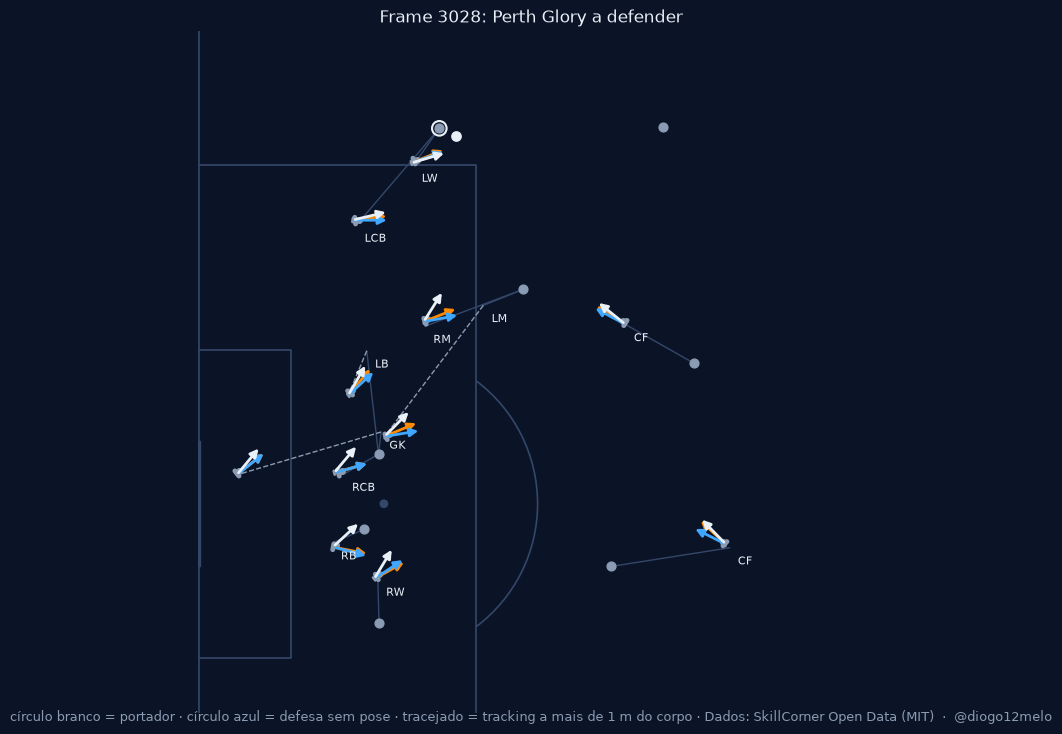

,posicao,tem_pose,dist_atacante,lado_da_baliza,persistencia_s,dist_portador,desvio_atacante_ombros,desvio_atacante_tronco,desvio_atacante_cabeca,desvio_portador_ombros,desvio_portador_tronco,desvio_portador_cabeca
0,LW,True,2.7,True,3.4,2.7,33.0,35.9,38.5,33.0,35.9,38.5
1,LCB,True,7.6,True,4.6,7.6,42.7,49.7,36.1,42.7,49.7,36.1
2,LM,True,2.6,True,4.6,10.9,0.9,12.5,23.7,81.2,94.7,58.5
3,RM,True,6.2,True,4.6,11.8,1.3,9.7,37.2,64.0,75.1,28.1
4,LB,True,6.2,False,4.6,13.9,133.6,126.0,143.5,21.9,29.4,12.0
5,CF,True,4.7,True,4.4,16.1,177.4,178.6,170.7,14.3,18.4,7.7
6,GK,True,1.3,False,4.6,18.4,135.1,134.9,146.8,40.5,40.8,28.8
7,RCB,True,2.4,True,1.4,21.4,14.2,14.3,20.1,58.8,59.0,24.5
8,RB,True,2.0,True,4.6,25.5,34.2,37.8,19.7,86.8,90.3,32.8
9,RW,True,2.6,True,1.0,27.1,117.6,122.1,147.4,53.1,48.6,23.3


In [26]:
desenhar_exemplo_marcacao(int(exemplos.iloc[0][1]))

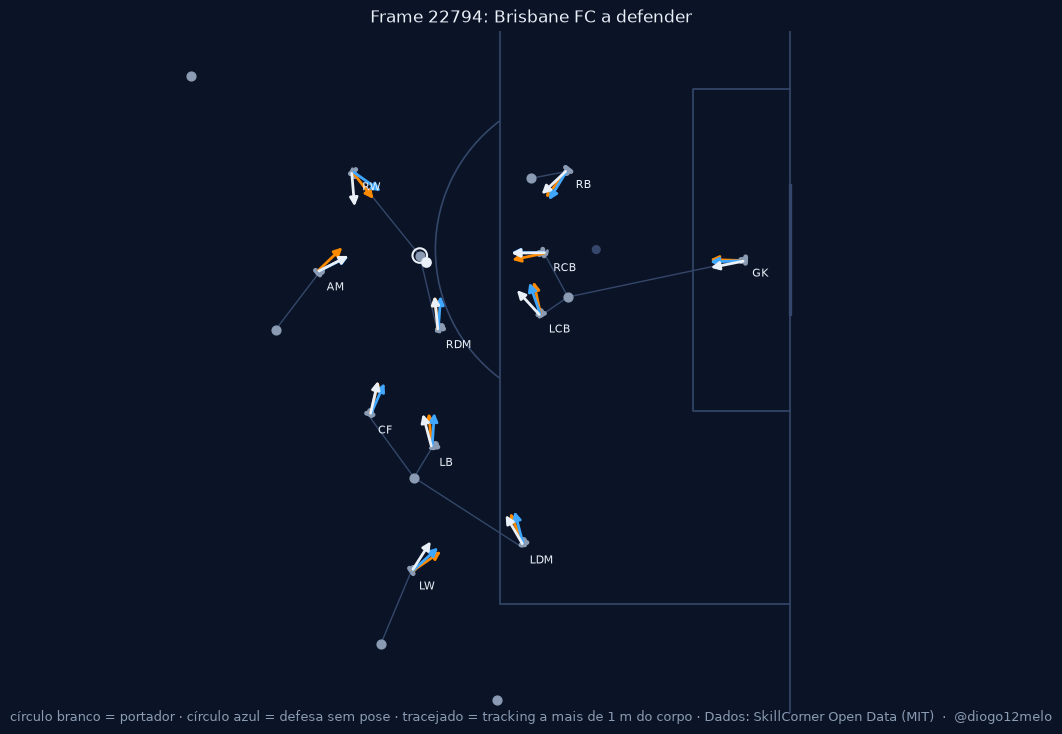

,posicao,tem_pose,dist_atacante,lado_da_baliza,persistencia_s,dist_portador,desvio_atacante_ombros,desvio_atacante_tronco,desvio_atacante_cabeca,desvio_portador_ombros,desvio_portador_tronco,desvio_portador_cabeca
0,RDM,True,4.4,True,1.0,4.4,7.8,17.3,7.4,7.8,17.3,7.4
1,AM,True,4.0,True,0.6,5.9,171.2,153.7,154.4,33.8,16.3,17.0
2,RW,True,6.0,False,1.0,6.0,1.1,15.9,33.9,1.1,15.9,33.9
3,RCB,True,2.8,False,0.4,7.1,106.7,118.6,117.7,11.2,0.6,0.2
4,LCB,True,1.9,False,1.0,7.7,67.7,74.8,98.1,51.3,44.2,20.9
5,CF,True,4.3,False,1.0,9.6,130.2,120.0,131.0,3.6,6.6,4.4
6,RB,True,2.1,True,1.0,9.7,41.2,47.6,32.5,22.4,28.7,13.7
7,LB,True,1.9,True,1.0,11.0,143.7,152.7,134.0,1.9,7.1,11.6
8,LDM,True,7.3,True,1.0,17.5,34.9,42.4,26.9,3.0,4.4,11.1
9,LW,True,4.4,True,1.0,18.1,147.0,154.7,170.3,54.0,46.4,30.8


In [27]:
desenhar_exemplo_marcacao(int(exemplos.iloc[1][1]))

## 8. O que cada parte faz, em linguagem corrente

- **Tabela de trabalho.** O tracking tem 10 fotografias por segundo e a pose 25. Só de 5 em 5
  fotografias de pose é que as duas foram tiradas no mesmo instante; fica-se com essas (5 por
  segundo) e só dentro das posses de bola. Cada linha diz onde está um jogador, se tem pose e
  onde estão a cabeça, os ombros e as ancas.
- **Alinhamento.** Primeiro confirma-se que a conta dos 2,5 frames é a certa: desloca-se o frame
  da pose para a frente e para trás e vê-se que a distância é menor sem deslocamento. Depois
  mede-se quanto a posição do tracking difere da posição que vem com a pose e do centro das ancas,
  e mostram-se os casos em que o tracking põe o jogador a vários metros do próprio corpo.
- **Orientação.** A frente do corpo calcula-se de três formas (ombros, ombros e ancas, cabeça).
  Compara-se quanto as três concordam e quanto cada uma salta de um instante para o seguinte.
- **Posses.** Conta-se quantas posses há, quanto duram e quantos instantes alinhados tem cada uma.
- **Cobertura.** Para várias formas de escolher os defesas que interessam (todos, sem o
  guarda-redes, perto da bola), vê-se que parte deles tem pose e em quantos instantes têm todos.
- **Marcação.** Para cada defesa mede-se a distância ao atacante mais próximo, se está do lado da
  baliza, durante quanto tempo é o mesmo atacante e se o corpo aponta para ele e para quem tem a
  bola. São medidas, não uma regra.

## 9. Síntese da fase

Os números abaixo são calculados nas secções anteriores (jogo 1925299, posses de bola, frames
alinhados a 5 por segundo).

In [28]:
cob = pd.DataFrame({nome: cobertura(defesas[filtro]) for nome, filtro in DEFINICOES.items()}).T
conc, var = diferencas.median(), variacoes.median()
ancas = com_pose_todos["dist_ancas"]
longe_nao_detetado = (com_pose_todos.loc[~com_pose_todos["detetado"], "dist_ancas"] > LONGE).mean()
Markdown(f"""
- **Tabela de trabalho:** {len(tabela)} jogador-frames em {tabela['frame'].nunique()} frames alinhados
  ({pt(tabela['frame'].nunique() / FPS_ALINHADO / 60)} min de posse), {tabela['jogador'].nunique()} jogadores.
- **Alinhamento:** timestamps iguais nos frames alinhados testados; a distância mínima entre tracking e
  ficheiro da pose acontece com desvio {teste_desvio.idxmin()} (mediana {pt(teste_desvio.min(), 2)} m).
  Nos frames da tabela, tracking ↔ centro das ancas: mediana {pt(ancas.median(), 2)} m, p90 {pt(ancas.quantile(0.9), 2)} m;
  ficheiro da pose ↔ centro das ancas: p99 {pt(com_pose_todos['dist_pose_ancas'].quantile(0.99), 2)} m.
  O tracking fica a mais de {LONGE} m do corpo em {pt(100 * (ancas > LONGE).mean())}% dos jogador-frames com pose
  ({pt(100 * longe_nao_detetado)}% quando o tracking marca o jogador como não detetado).
- **Orientação:** nariz à frente do pescoço em {pt(100 * nariz_a_frente(com_pose, 'ombros').mean())}% (ombros) e
  {pt(100 * nariz_a_frente(com_pose, 'tronco').mean())}% (tronco). Diferença mediana entre versões:
  {', '.join(f'{k} {v:.0f}°' for k, v in conc.items())}. Variação mediana entre frames seguidos (0,2 s):
  {', '.join(f'{k} {v:.0f}°' for k, v in var.items())}.
- **Posses:** {len(tabela_posses)} posses, {int((tabela_posses['frames_alinhados'] == 0).sum())} sem nenhum frame alinhado;
  {frames_sem_jogadores} frames alinhados sem jogadores no tracking.
- **Cobertura nos defesas:** com pose em {pt(cob.loc['todos os defesas', '% defesa-frames com pose'])}% dos defesa-frames
  (todos), {pt(cob.loc['a menos de 30 m da bola', '% defesa-frames com pose'])}% a menos de 30 m da bola e
  {pt(cob.loc['a menos de 20 m da bola', '% defesa-frames com pose'])}% a menos de 20 m. Todos os defesas a menos de 20 m
  com pose em {pt(cob.loc['a menos de 20 m da bola', '% frames com todos com pose'])}% dos frames; a menos de 30 m,
  em {pt(cob.loc['a menos de 30 m da bola', '% frames com todos com pose'])}%.
- **Marcação:** distância mediana ao atacante mais próximo {pt(marcacao['dist_atacante'].median())} m; do lado da
  baliza em {pt(100 * marcacao['lado_da_baliza'].mean())}% dos defesa-frames; persistência mediana
  {pt(marcacao['persistencia_s'].median())} s.
""")


- **Tabela de trabalho:** 196130 jogador-frames em 8915 frames alinhados
  (29,7 min de posse), 32 jogadores.
- **Alinhamento:** timestamps iguais nos frames alinhados testados; a distância mínima entre tracking e
  ficheiro da pose acontece com desvio 0 (mediana 0,23 m).
  Nos frames da tabela, tracking ↔ centro das ancas: mediana 0,22 m, p90 0,54 m;
  ficheiro da pose ↔ centro das ancas: p99 0,23 m.
  O tracking fica a mais de 3 m do corpo em 1,2% dos jogador-frames com pose
  (49,0% quando o tracking marca o jogador como não detetado).
- **Orientação:** nariz à frente do pescoço em 99,9% (ombros) e
  99,9% (tronco). Diferença mediana entre versões:
  ombros ↔ tronco (ombros + ancas) 6°, ombros ↔ cabeça 18°, tronco (ombros + ancas) ↔ cabeça 19°. Variação mediana entre frames seguidos (0,2 s):
  ombros 11°, tronco (ombros + ancas) 7°, cabeça 8°.
- **Posses:** 1054 posses, 130 sem nenhum frame alinhado;
  14 frames alinhados sem jogadores no tracking.
- **Cobertura nos defesas:** com pose em 64,5% dos defesa-frames
  (todos), 82,8% a menos de 30 m da bola e
  92,7% a menos de 20 m. Todos os defesas a menos de 20 m
  com pose em 78,4% dos frames; a menos de 30 m,
  em 37,0%.
- **Marcação:** distância mediana ao atacante mais próximo 5,6 m; do lado da
  baliza em 66,2% dos defesa-frames; persistência mediana
  2,2 s.


**Limitações desta preparação**
- Um só jogo; o segundo jogo com pose (1996435) prepara-se com o mesmo script.
- A tabela tem 5 frames por segundo, os únicos em que pose e tracking coincidem sem interpolação.
- As posições do tracking e da pose são geradas em separado pela SkillCorner; a diferença entre
  ambas está medida na secção 3. As características de marcação usam a posição do tracking; as
  orientações, o corpo da pose.
- A distância à bola usa a bola do tracking, que também é estimada quando não é vista.
- A persistência de um frame usa o trecho inteiro a que pertence, incluindo frames seguintes.